In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

plt.rcParams["animation.html"] = "jshtml"

In [2]:
def eden_model(time):
    """
    Simulates the 2D Eden model

    Args:
        length (int): number of lattice points in one dimension
        width (int): number of lattice points in one dimension
        time (int): number of steps to simulate ballistic deposition for

    Returns:
        particles (array of 3-tuples): positions and heights of particles added to surface at each time step
    """
    particles = np.zeros((time, 2))
    particles[0] = [0, 0]
    boundary = [(0, 1), (0, -1), (-1, 0), (1, 0)]

    for t in range(time):
        point = boundary.pop(np.random.randint(0, len(boundary)))
        particles[t] = point
        add_boundary(point, boundary, particles)

    return particles

# https://stackoverflow.com/questions/71438019/how-do-i-check-if-a-numpy-tuple-is-in-a-2d-numpy-array-of-tuples
def add_boundary(point, boundary, particles):
    if (point[0]-1, point[1]) not in boundary and not (((point[0]-1, point[1])==particles).all(axis=1).any()):
        boundary.append((point[0]-1, point[1]))
    if (point[0]+1, point[1]) not in boundary and not (((point[0]+1, point[1])==particles).all(axis=1).any()):
        boundary.append((point[0]+1, point[1]))
    if (point[0], point[1]-1) not in boundary and not (((point[0], point[1]-1)==particles).all(axis=1).any()):
        boundary.append((point[0], point[1]-1))
    if (point[0], point[1]+1) not in boundary and not (((point[0], point[1]+1)==particles).all(axis=1).any()):
        boundary.append((point[0], point[1]+1))

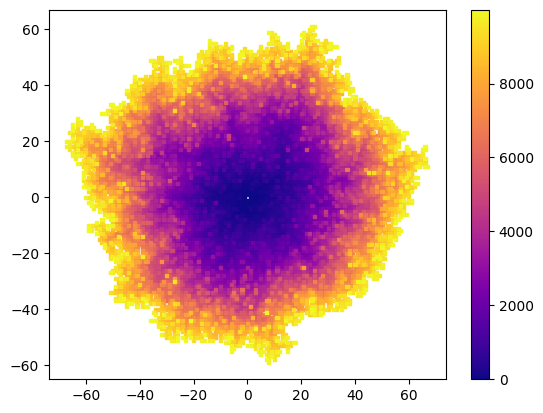

In [3]:
TIME = 10000

eden_surface = eden_model(TIME)
plt.scatter(eden_surface[:, 0], eden_surface[:, 1], c=range(TIME), cmap='plasma', s=5, marker='s')
plt.colorbar()
plt.show()

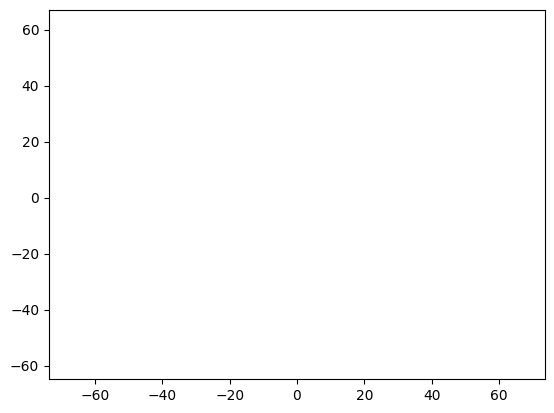

In [5]:
fig, ax = plt.subplots()
scat = ax.scatter(eden_surface[0, 0], eden_surface[0, 1], edgecolors='black', s=5)
ax.set(xlim=[1.1 * np.min(eden_surface[:, 0]), 1.1 * np.max(eden_surface[:, 0])], 
       ylim=[1.1 * np.min(eden_surface[:, 1]), 1.1 * np.max(np.max(eden_surface[:, 1]))])

def update(frame):
    eden_x = eden_surface[:100*frame, 0]
    eden_y = eden_surface[:100*frame, 1]

    # Update scatter plot
    # data = np.stack([surface_x, surface_y, surface_z], axis=1)
    data = np.stack([eden_x, eden_y], axis = 1)
    scat.set_offsets(data)

    return scat

ani = animation.FuncAnimation(fig=fig, func=update, frames=TIME//100, interval=45)
ani